# Classic Sparsity Experiment (n >> p)

## 0. Imports

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Import data generation
from data_generation.generate_data import generate_data

# Import plots
from plots.coefficient_plot import coefficient_plot
from plots.metrics import compute_metrics

# Import models
from models.OLS import run_ols
from models.LASSO import run_lasso, run_lasso_cv
from models.Ridge import run_ridge, run_ridge_cv
from models.ElasticNet import run_elasticnet_alpha, run_elasticnet_l1ratio, run_elasticnet_cv

# Removing Warnings
import warnings


In [43]:
warnings.filterwarnings('ignore')

## 1. Generating Data

GENERATED DATA:
Shape of X: (200, 50)

X Matrix: 
 [[-1.15655522e+00  1.99209441e+00  4.00641638e-01 ... -1.59761973e+00
   1.60567796e+00  1.15166558e+00]
 [-1.02636921e+00 -1.48969310e-01  2.08604705e+00 ... -1.54896053e+00
  -1.54572979e+00 -3.13672612e-04]
 [-1.44392555e+00  2.41877778e+00 -2.12089670e-01 ... -1.25656534e+00
   1.34593501e+00  7.83159888e-01]
 ...
 [-5.86531270e-01  1.70463771e-01 -1.28716357e+00 ... -4.11426607e-01
  -6.58248412e-01 -4.71124652e-01]
 [-3.78759837e-01  4.28342051e-01  1.09018347e+00 ... -3.73368425e-01
   4.50613049e-01 -2.03461141e-01]
 [ 9.11681467e-02 -5.79639997e-02 -2.26942466e-01 ... -1.13417115e+00
  -1.42287691e+00  1.17998853e+00]]
Shape of y: (200,)

y Vector: 
 [-7.75419804e+01  1.59727005e+02  6.12646590e+01 -2.18815468e+02
 -7.36987512e+01 -8.86924643e+01 -1.49760119e+02 -6.85094811e+01
  5.21103509e+00 -6.33466747e+01 -9.69805634e+01 -1.62534908e+02
  1.04904570e+02 -1.63133747e+01  1.06370663e+02  2.17203337e+01
 -2.49837367e+02 -1.4

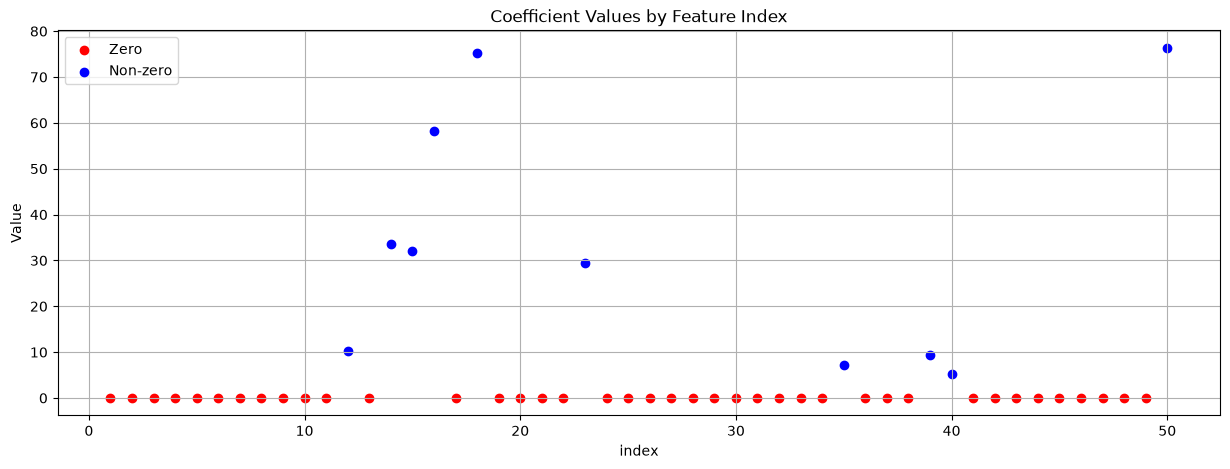

In [44]:
X_train, X_test, y_train, y_test, coef = generate_data(
    n_samples=200,
    n_features=50,
    n_informative=10,
    noise=0.0,
    effective_rank=None,
    tail_strength=0.5
)

coefficient_plot(coef)


## 2. Ordinary Least Square

MAE: 0.00
MSE: 0.00
RMSE: 0.00
R² Score: 1.00
Number of non zero coefs: 49
Max coef magnitude: 80.4388
Mean coef magnitude: 6.7096


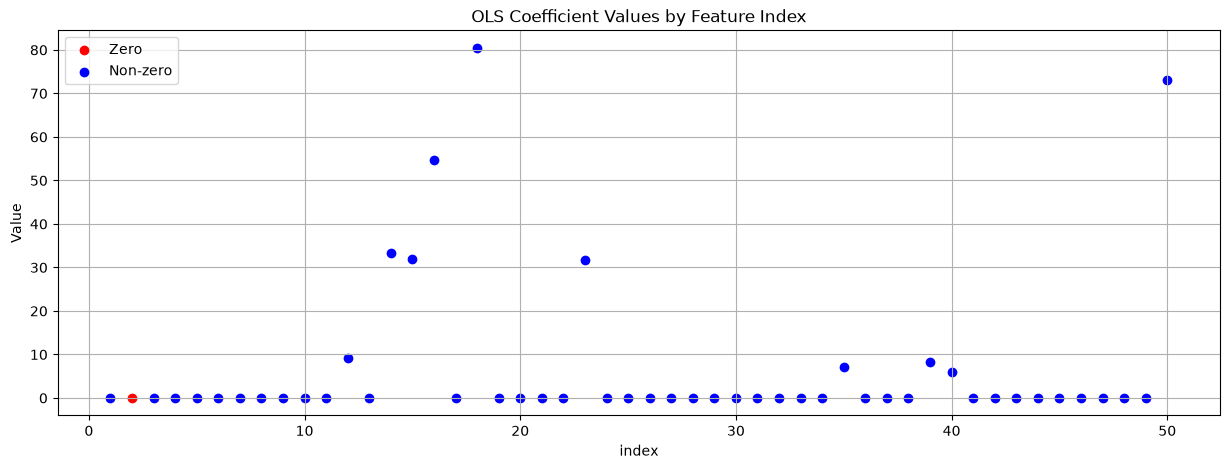

In [45]:
OLS_model = run_ols(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

## 3. Least Absolute Shrinkage and Selection Operator

Metrics for i = 0.001:
MAE: 0.01
MSE: 0.00
RMSE: 0.01
R² Score: 1.00
Number of non zero coefs: 30
Max coef magnitude: 80.4393
Mean coef magnitude: 6.7098


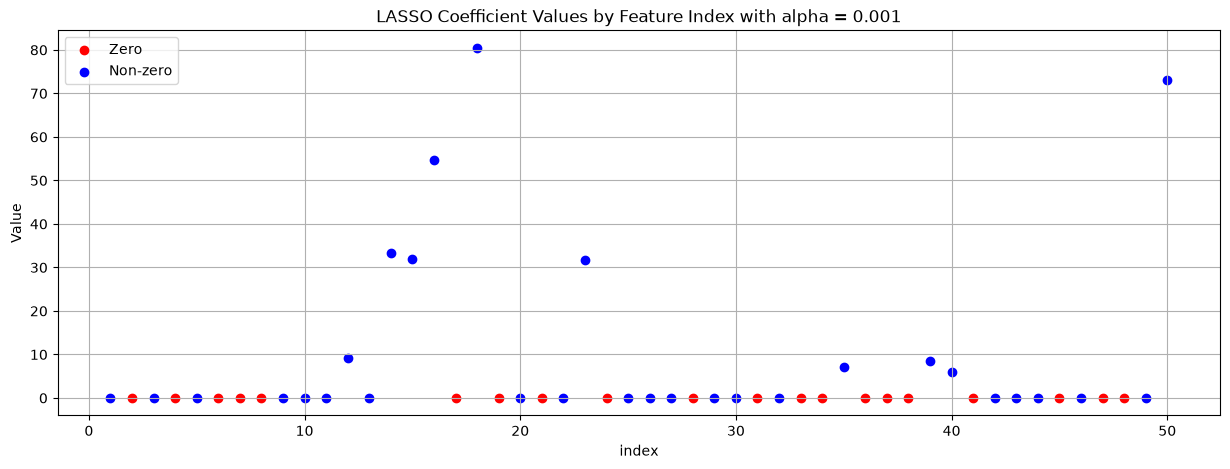

Metrics for i = 0.01:
MAE: 0.04
MSE: 0.00
RMSE: 0.04
R² Score: 1.00
Number of non zero coefs: 10
Max coef magnitude: 80.4276
Mean coef magnitude: 6.7073


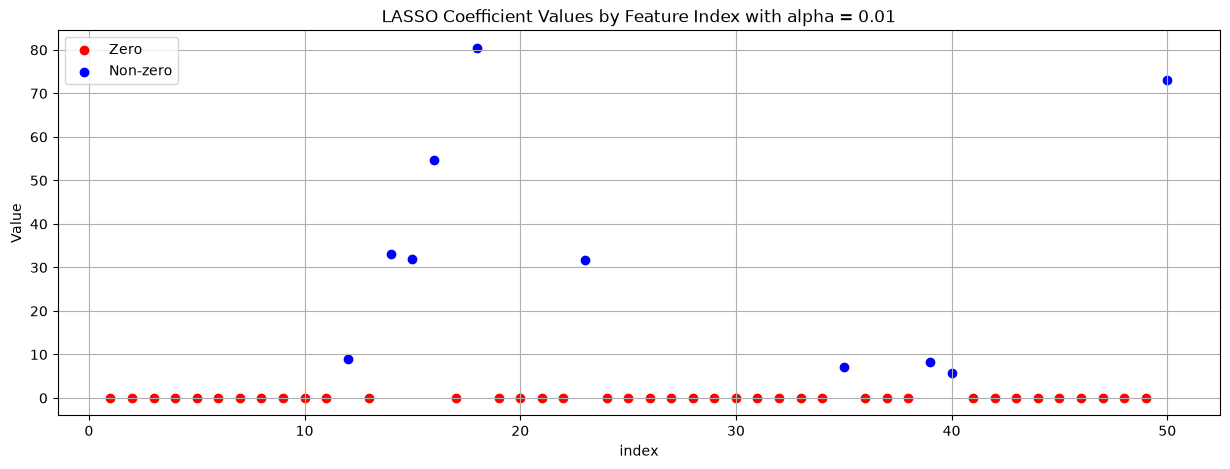

Metrics for i = 0.1:
MAE: 0.35
MSE: 0.17
RMSE: 0.42
R² Score: 1.00
Number of non zero coefs: 10
Max coef magnitude: 80.3259
Mean coef magnitude: 6.6867


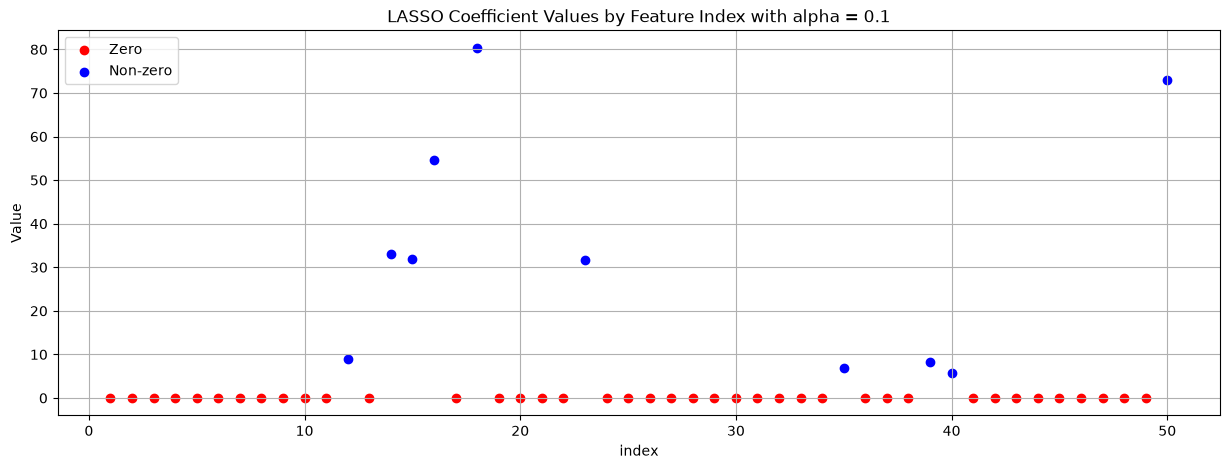

Metrics for i = 1.0:
MAE: 3.48
MSE: 17.43
RMSE: 4.18
R² Score: 1.00
Number of non zero coefs: 10
Max coef magnitude: 79.3081
Mean coef magnitude: 6.4811


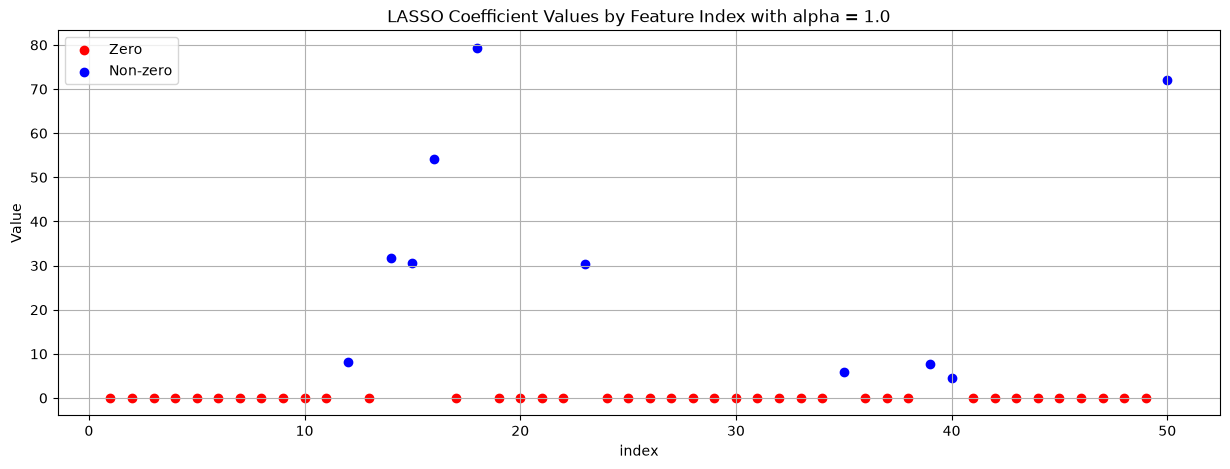

Metrics for i = 10.0:
MAE: 29.99
MSE: 1366.42
RMSE: 36.97
R² Score: 0.93
Number of non zero coefs: 6
Max coef magnitude: 69.1623
Mean coef magnitude: 4.7191


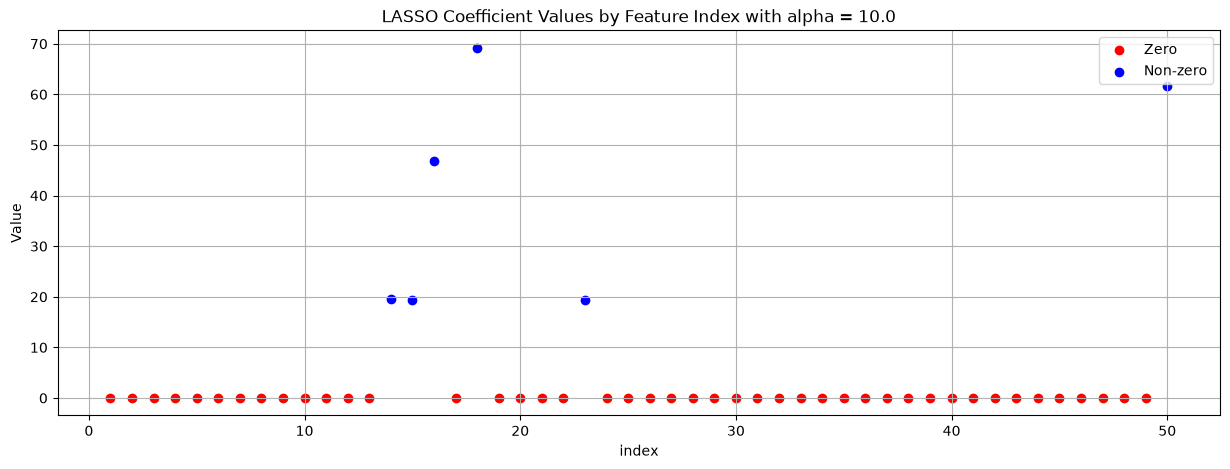

Metrics for i = 100.0:
MAE: 118.91
MSE: 19977.68
RMSE: 141.34
R² Score: -0.02
Number of non zero coefs: 0
Max coef magnitude: 0.0000
Mean coef magnitude: 0.0000


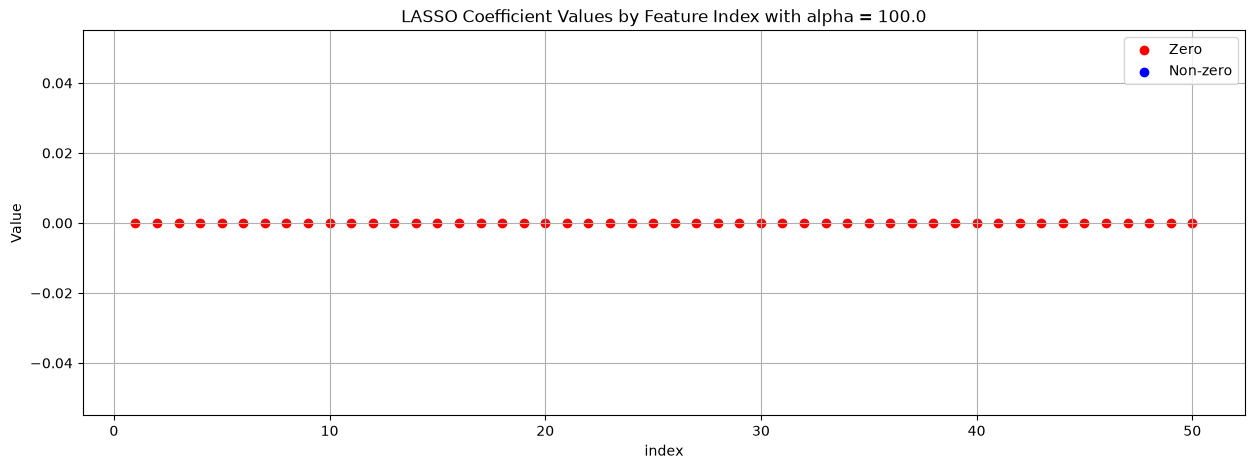

In [46]:
LASSO_models = run_lasso(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

### Best alpha for LASSO

MAE: 0.79
MSE: 0.89
RMSE: 0.95
R² Score: 1.00
Number of non zero coefs: 10
Max coef magnitude: 80.1830
Mean coef magnitude: 6.6579


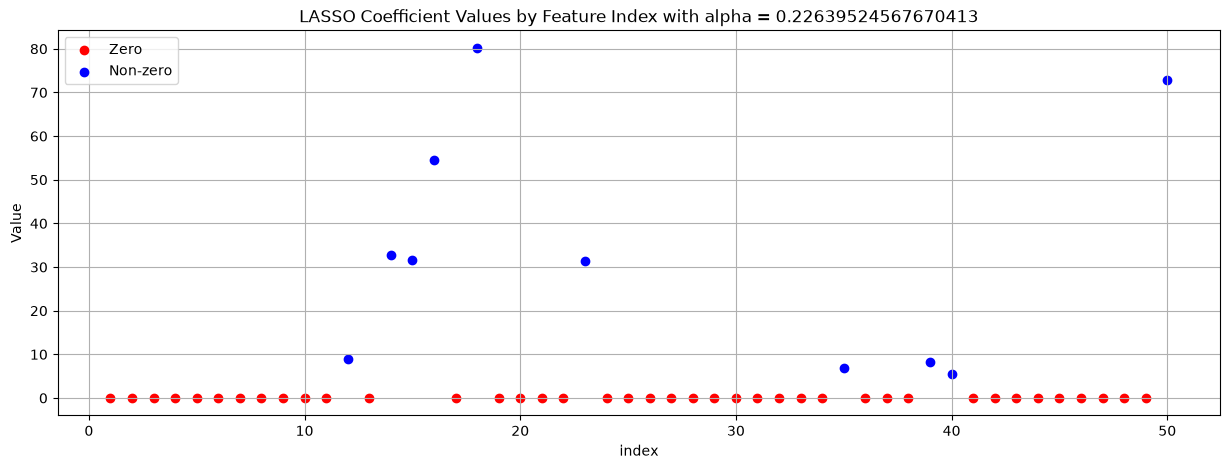

In [47]:
LASSOCV_model = run_lasso_cv(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

### Variable Selection via LASSO for Linear Regression
In this approach, LASSO select the features. Subsequently, an Ordinary Least Sqaures (OLS) regression is fitted on the selected subset of variables.

MAE: 0.79
MSE: 0.89
RMSE: 0.95
R² Score: 1.00
Number of non zero coefs: 10
Max coef magnitude: 80.1830
Mean coef magnitude: 6.6579


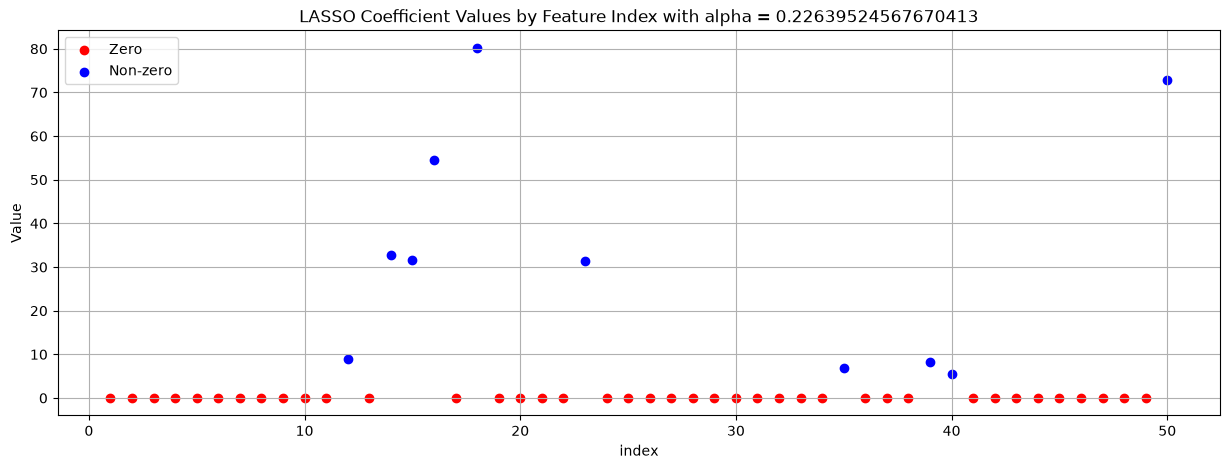

In [48]:
LASSOCV_model = run_lasso_cv(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

In [49]:
# printing Non-zero coefs
# np.nonzeros returns a tuple, [0] is the vector
nonzero = np.nonzero(LASSOCV_model.coef_.copy())[0]
for i in nonzero:
    print(f"idx: {i}, value: {LASSOCV_model.coef_[i]}")

idx: 11, value: 8.853731690036259
idx: 13, value: 32.859404206946564
idx: 14, value: 31.63881251145158
idx: 15, value: 54.54795078375348
idx: 17, value: 80.18300546997244
idx: 22, value: 31.407955472394445
idx: 34, value: 6.774392176955716
idx: 38, value: 8.208444354696189
idx: 39, value: 5.539151899581775
idx: 49, value: 72.87978301834946


In [50]:
# filtering the columns
X_train_nonzero = X_train[:, nonzero]
X_test_nonzero = X_test[:, nonzero]

MAE: 0.00
MSE: 0.00
RMSE: 0.00
R² Score: 1.00
Number of non zero coefs: 10
Max coef magnitude: 80.4388
Mean coef magnitude: 33.5480


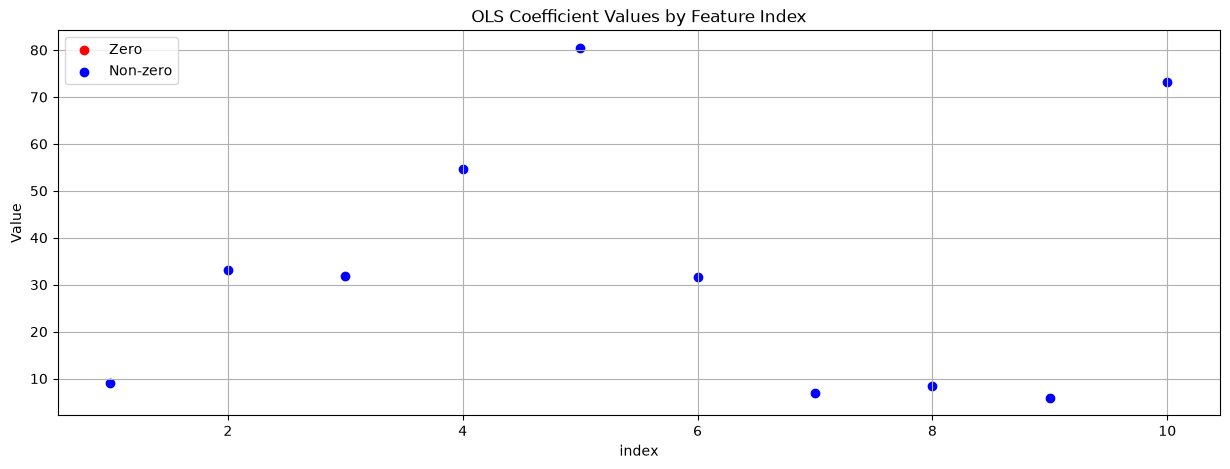

In [51]:
# training the model based on features whose coefficient is nonzero
OLS_model = run_ols(X_train_nonzero, X_test_nonzero, y_train, y_test, compute_metrics, coefficient_plot)

## 4. Ridge

Metrics for i = 0.001:
MAE: 0.00
MSE: 0.00
RMSE: 0.00
R² Score: 1.00
Number of non zero coefs: 50
Max coef magnitude: 80.4381
Mean coef magnitude: 6.7096


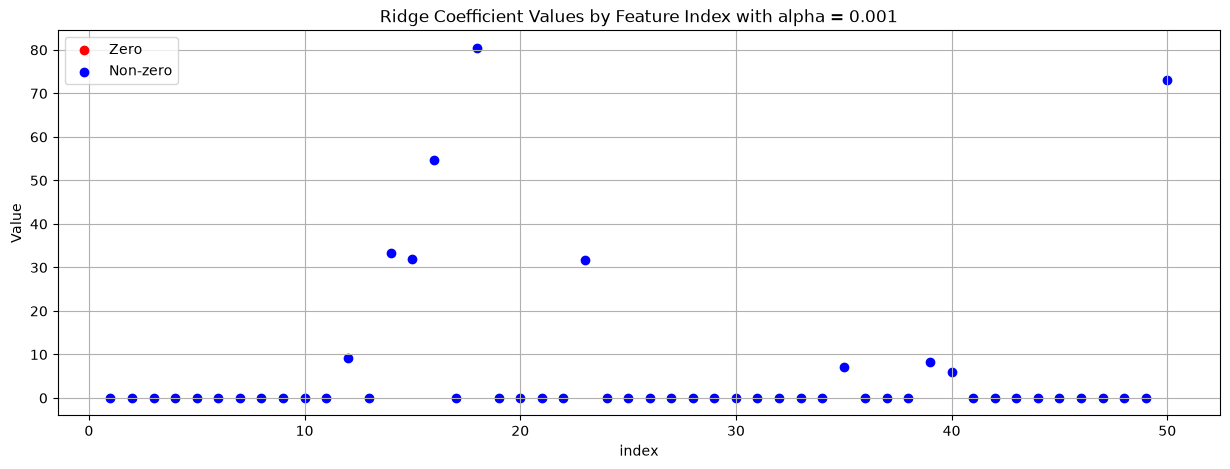

Metrics for i = 0.01:
MAE: 0.01
MSE: 0.00
RMSE: 0.01
R² Score: 1.00
Number of non zero coefs: 50
Max coef magnitude: 80.4322
Mean coef magnitude: 6.7097


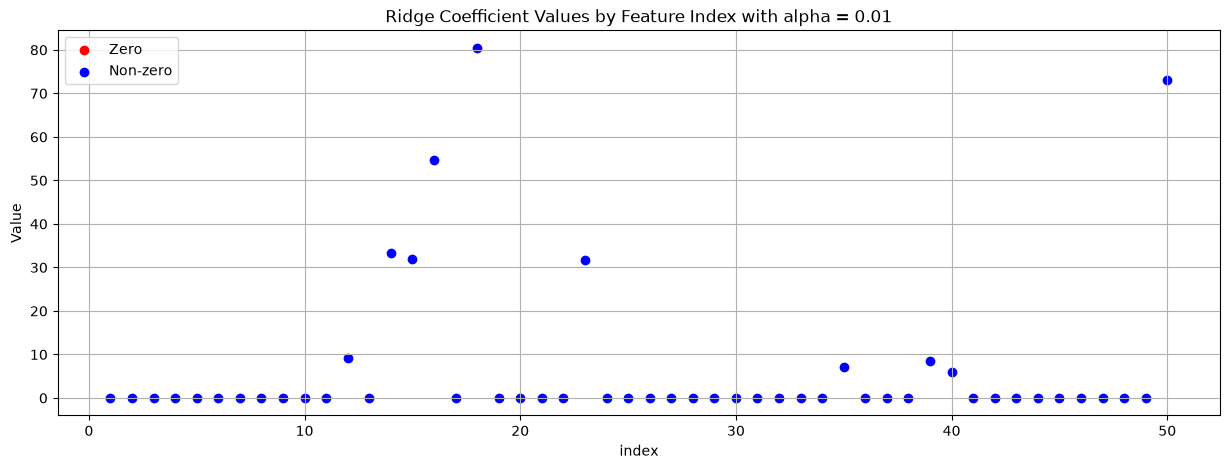

Metrics for i = 0.1:
MAE: 0.11
MSE: 0.02
RMSE: 0.14
R² Score: 1.00
Number of non zero coefs: 50
Max coef magnitude: 80.3736
Mean coef magnitude: 6.7105


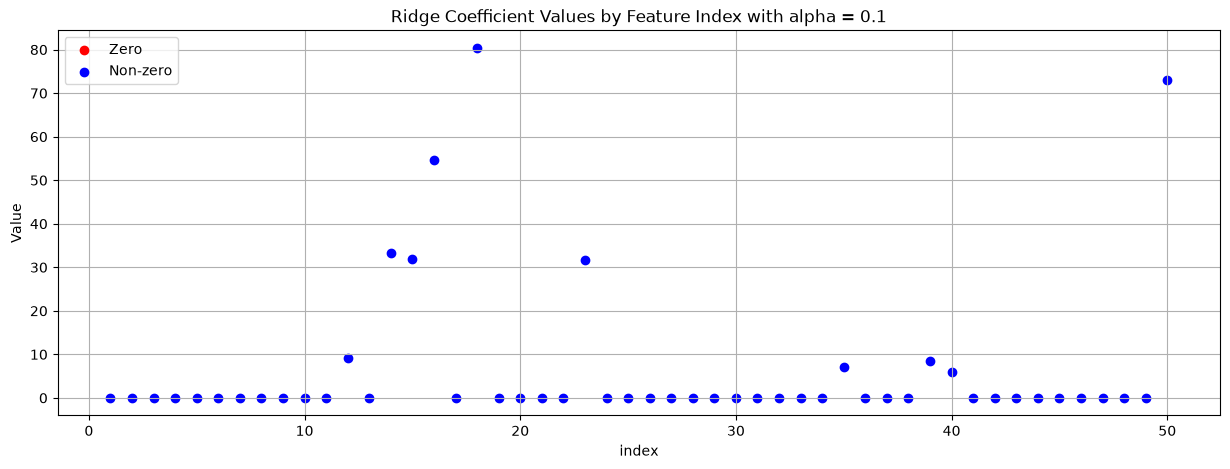

Metrics for i = 1.0:
MAE: 1.11
MSE: 1.92
RMSE: 1.38
R² Score: 1.00
Number of non zero coefs: 50
Max coef magnitude: 79.7927
Mean coef magnitude: 6.7176


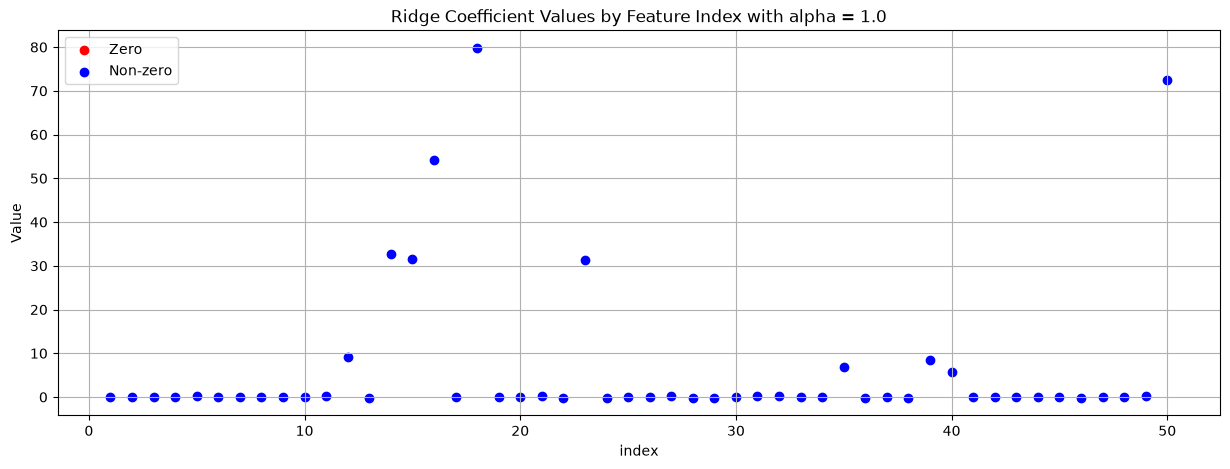

Metrics for i = 10.0:
MAE: 9.85
MSE: 151.64
RMSE: 12.31
R² Score: 0.99
Number of non zero coefs: 50
Max coef magnitude: 74.4750
Mean coef magnitude: 6.7250


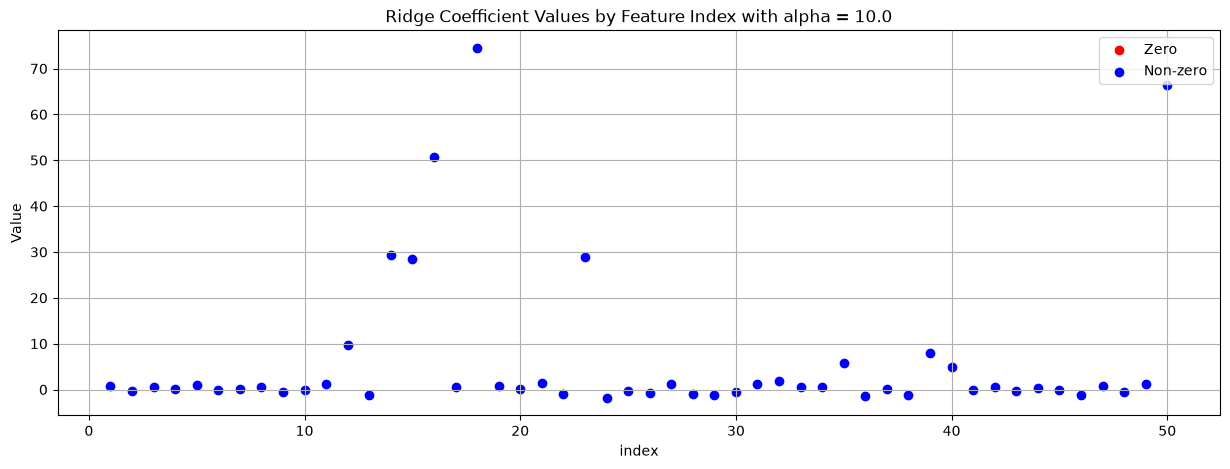

Metrics for i = 100.0:
MAE: 52.97
MSE: 4022.43
RMSE: 63.42
R² Score: 0.79
Number of non zero coefs: 50
Max coef magnitude: 46.1569
Mean coef magnitude: 5.5391


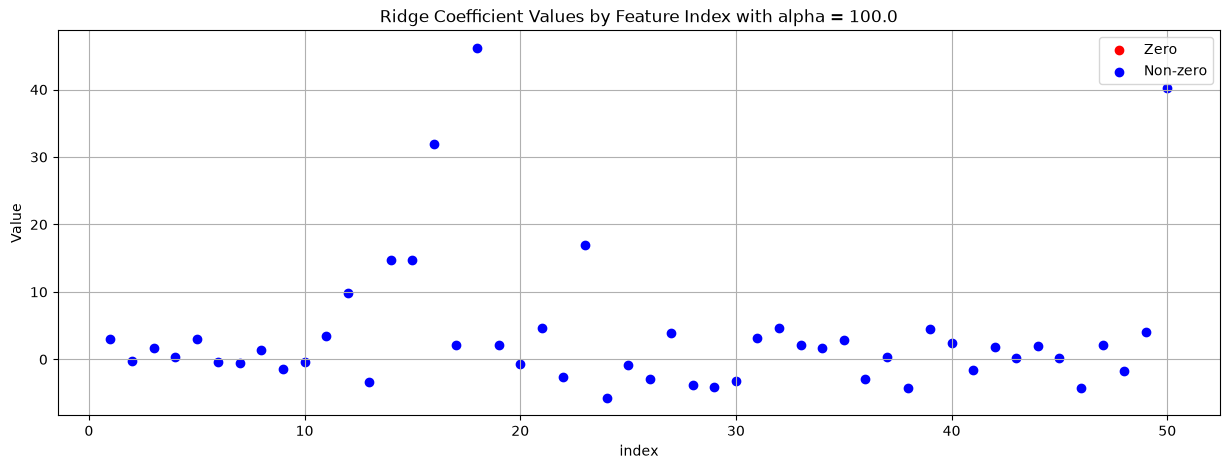

In [52]:
Ridge_models = run_ridge(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

### Ridge Best Alpha

MAE: 0.11
MSE: 0.02
RMSE: 0.14
R² Score: 1.00
Number of non zero coefs: 50
Max coef magnitude: 80.3736
Mean coef magnitude: 6.7105


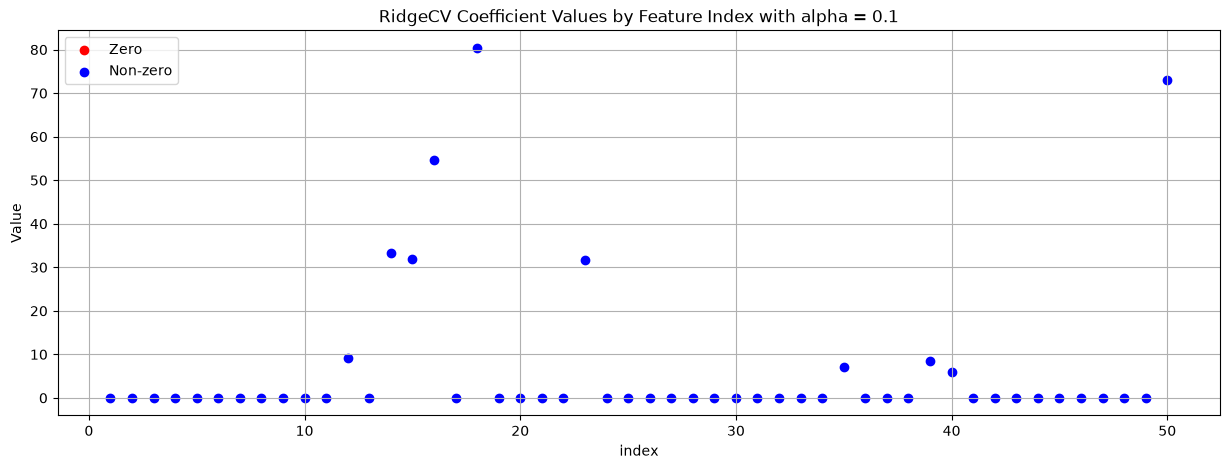

In [53]:
RidgeCV_model = run_ridge_cv(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

## 5. Elastic Net

Metrics for i = 0.001:
MAE: 0.09
MSE: 0.01
RMSE: 0.11
R² Score: 1.00
Number of non zero coefs: 48
Max coef magnitude: 80.3871
Mean coef magnitude: 6.7098


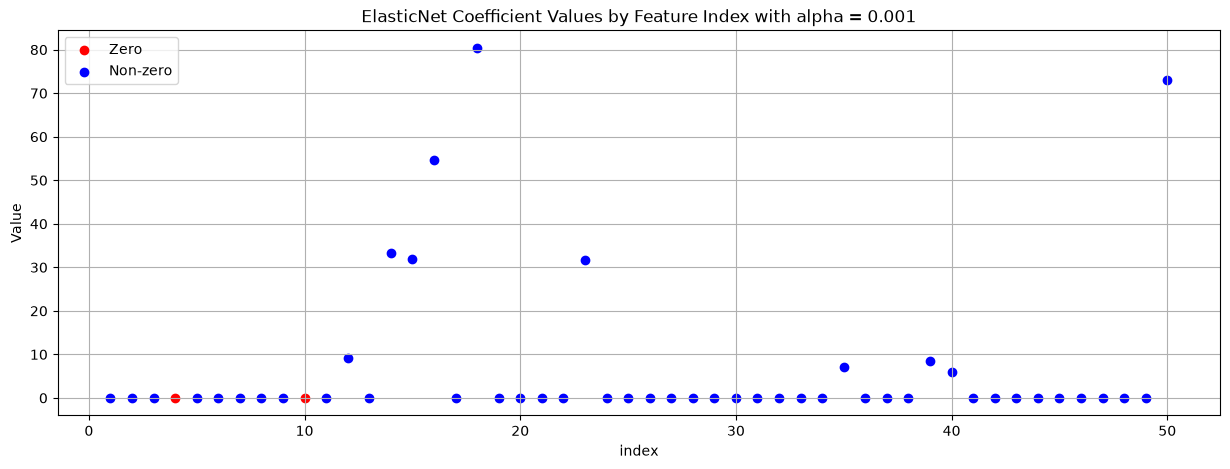

Metrics for i = 0.01:
MAE: 0.89
MSE: 1.22
RMSE: 1.11
R² Score: 1.00
Number of non zero coefs: 49
Max coef magnitude: 79.9204
Mean coef magnitude: 6.7094


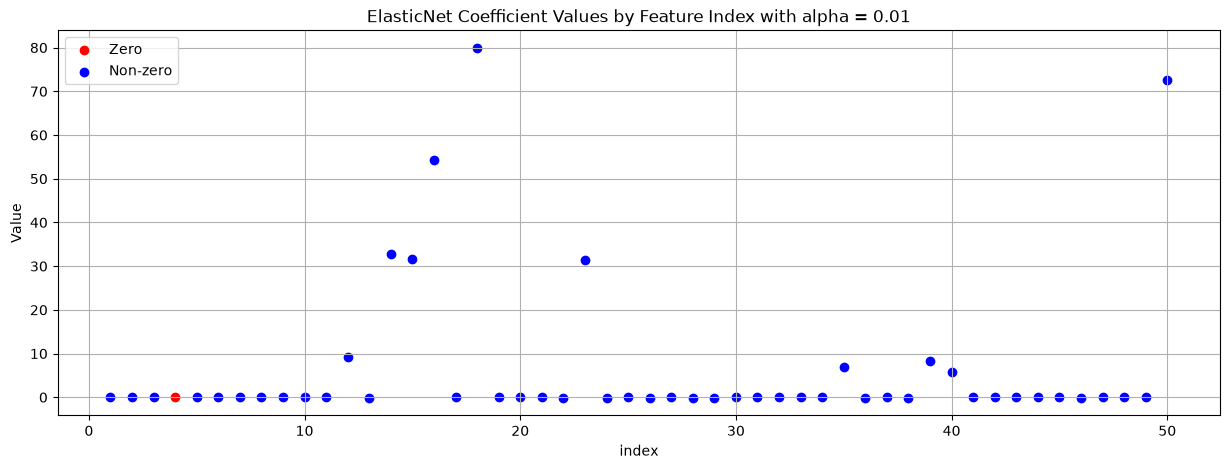

Metrics for i = 0.1:
MAE: 8.17
MSE: 101.92
RMSE: 10.10
R² Score: 0.99
Number of non zero coefs: 48
Max coef magnitude: 75.5737
Mean coef magnitude: 6.6704


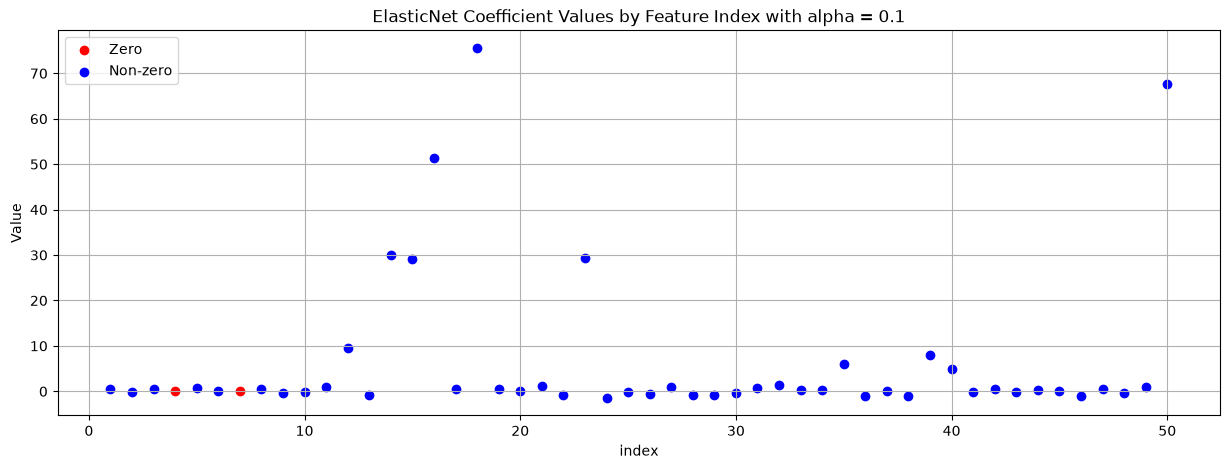

Metrics for i = 1.0:
MAE: 47.54
MSE: 3257.29
RMSE: 57.07
R² Score: 0.83
Number of non zero coefs: 44
Max coef magnitude: 50.1208
Mean coef magnitude: 5.5101


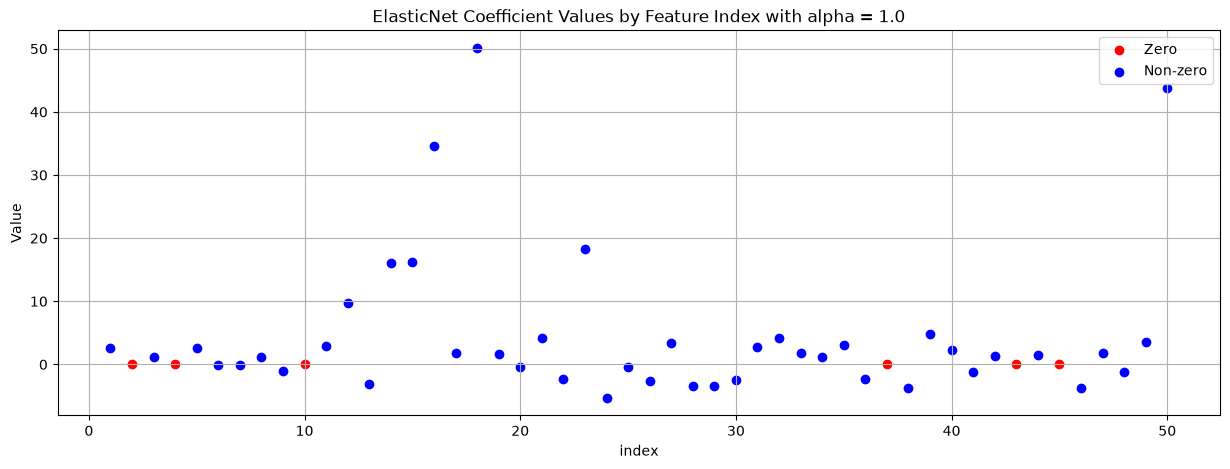

Metrics for i = 10.0:
MAE: 102.75
MSE: 14915.92
RMSE: 122.13
R² Score: 0.24
Number of non zero coefs: 34
Max coef magnitude: 12.0630
Mean coef magnitude: 1.3315


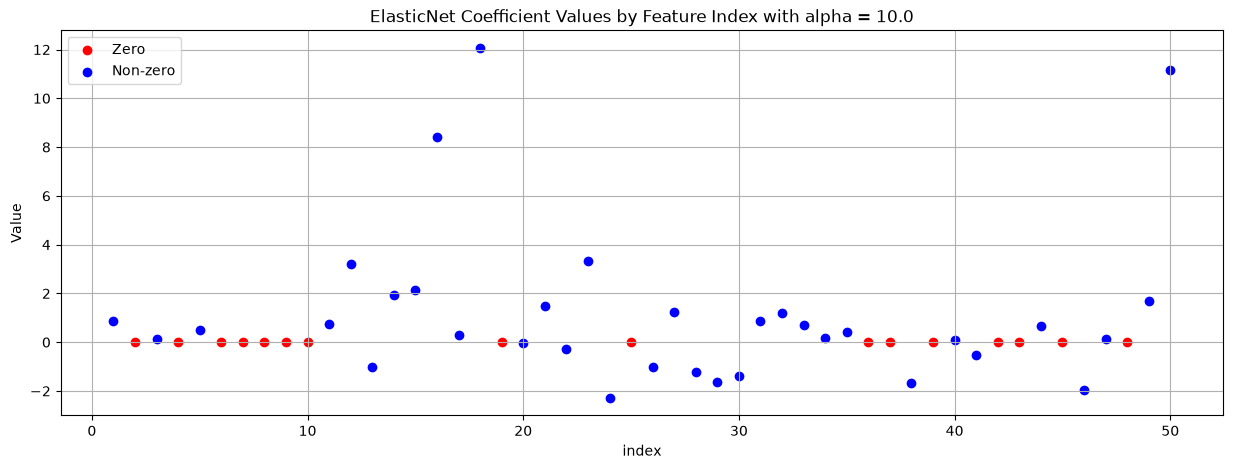

Metrics for i = 100.0:
MAE: 118.42
MSE: 19812.49
RMSE: 140.76
R² Score: -0.01
Number of non zero coefs: 3
Max coef magnitude: 0.5773
Mean coef magnitude: 0.0244


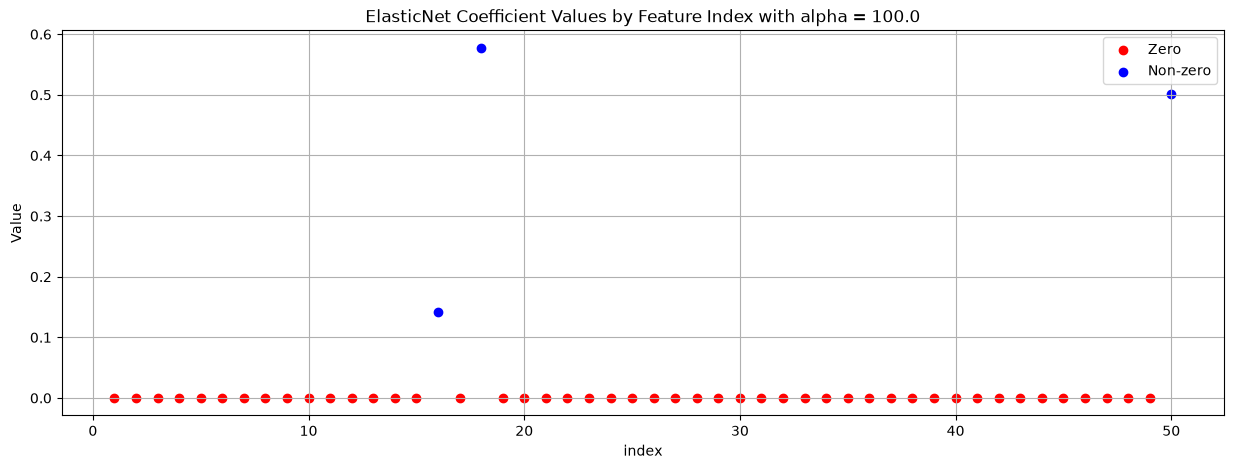

In [54]:
ElasticNet_alpha_models = run_elasticnet_alpha(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

Metrics for i = 0.0:
MAE: 65.75
MSE: 6129.10
RMSE: 78.29
R² Score: 0.69
Number of non zero coefs: 50
Max coef magnitude: 37.3131
Mean coef magnitude: 4.8301


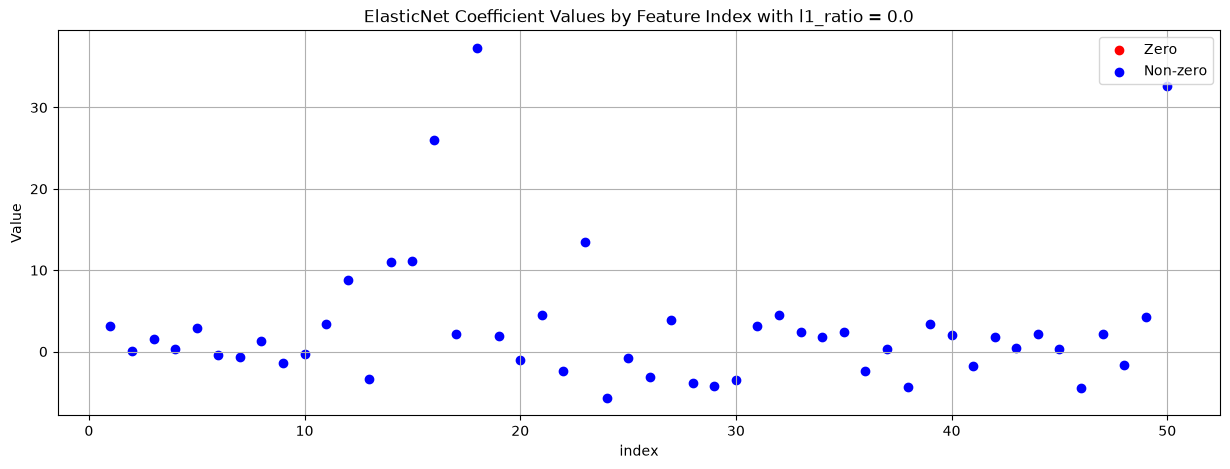

Metrics for i = 0.25:
MAE: 58.16
MSE: 4824.83
RMSE: 69.46
R² Score: 0.75
Number of non zero coefs: 49
Max coef magnitude: 42.6873
Mean coef magnitude: 5.1531


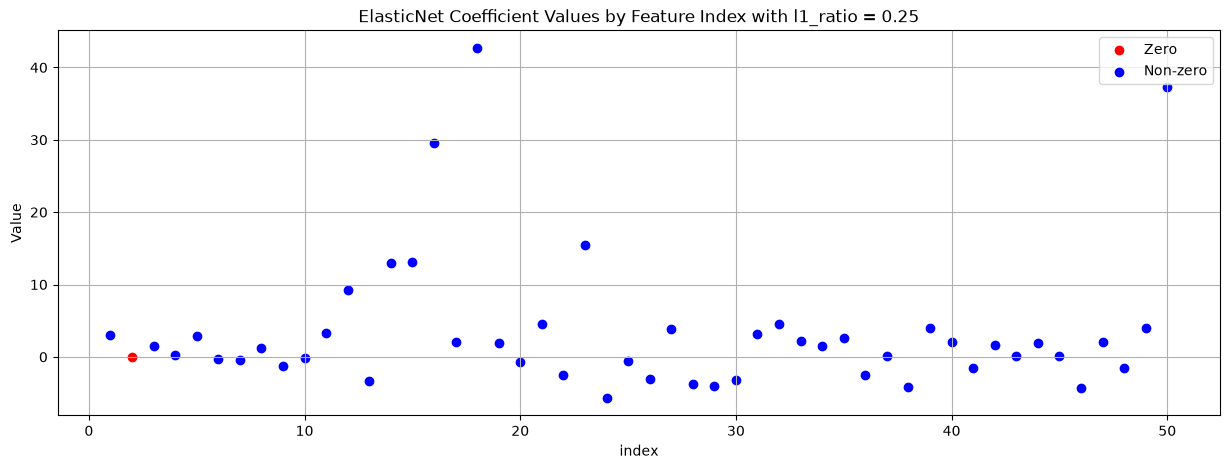

Metrics for i = 0.5:
MAE: 47.54
MSE: 3257.29
RMSE: 57.07
R² Score: 0.83
Number of non zero coefs: 44
Max coef magnitude: 50.1208
Mean coef magnitude: 5.5101


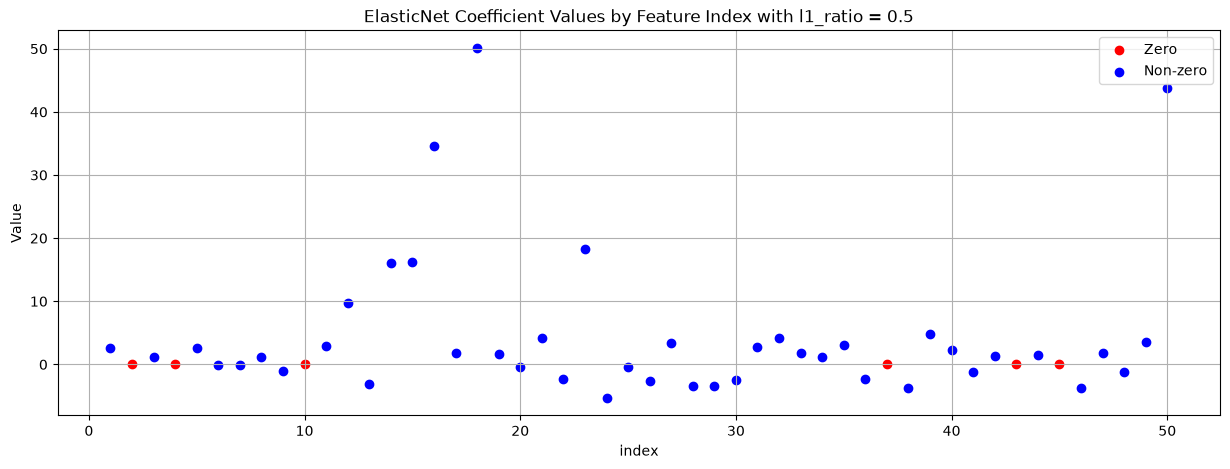

Metrics for i = 0.75:
MAE: 31.48
MSE: 1441.87
RMSE: 37.97
R² Score: 0.93
Number of non zero coefs: 40
Max coef magnitude: 61.2046
Mean coef magnitude: 5.8726


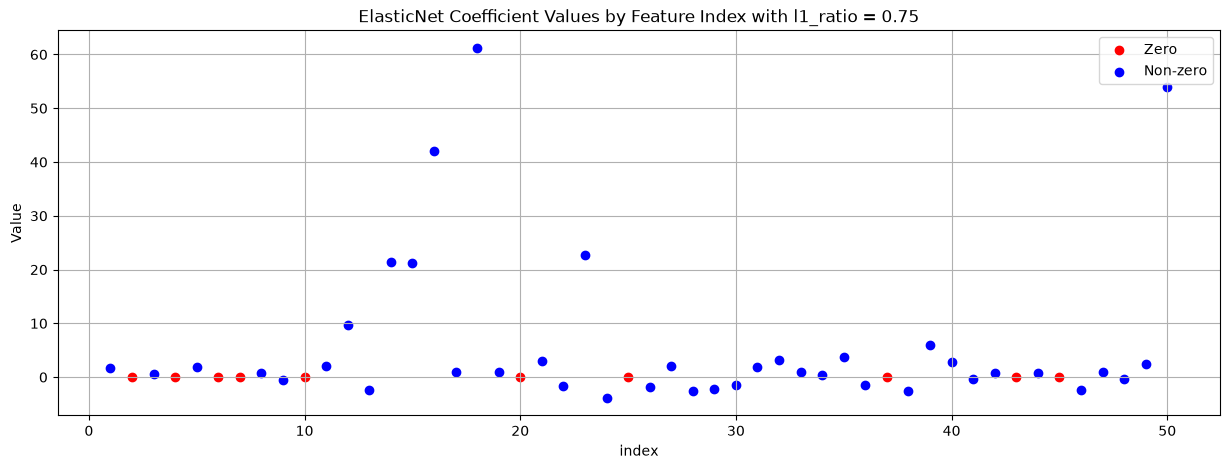

Metrics for i = 1.0:
MAE: 3.48
MSE: 17.43
RMSE: 4.18
R² Score: 1.00
Number of non zero coefs: 10
Max coef magnitude: 79.3081
Mean coef magnitude: 6.4811


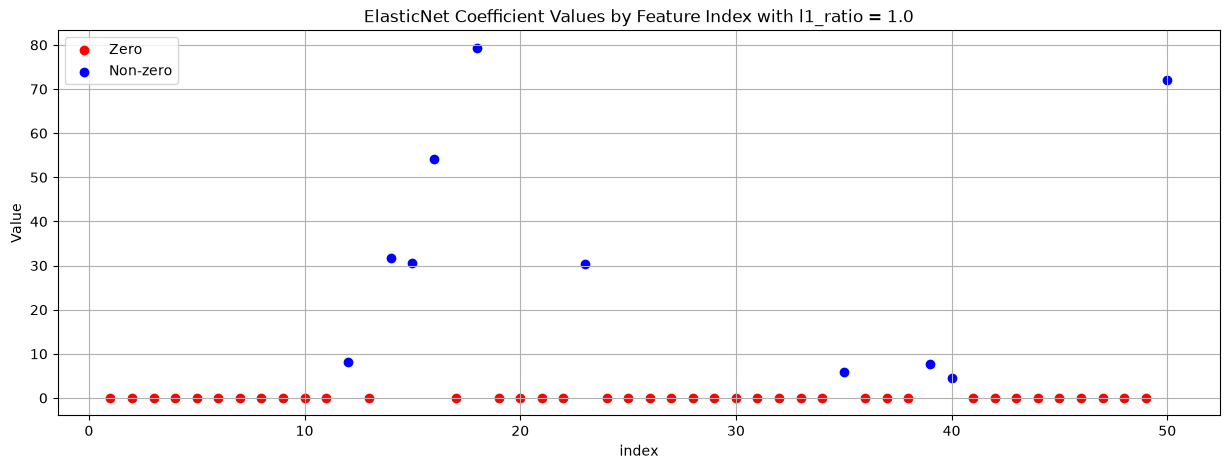

In [55]:
ElasticNet_l1_models = run_elasticnet_l1ratio(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

### Best alpha and l1 ratio for ElasticNet

MAE: 0.79
MSE: 0.89
RMSE: 0.95
R² Score: 1.00
Number of non zero coefs: 10
Max coef magnitude: 80.1830
Mean coef magnitude: 6.6579


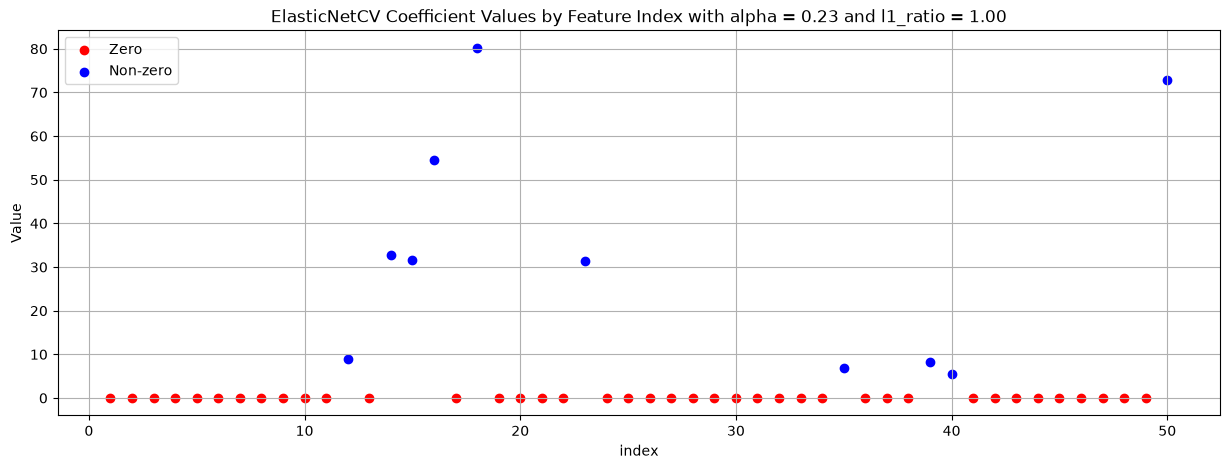

In [56]:
ElasticNet_model = run_elasticnet_cv(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)